# Signal Denoising: Mean vs Median Filters

Two kinds of noise need two different filters. This notebook tests that on signals where the clean version is known, so every claim is backed by a number (RMSE, SNR improvement).

The filters and metrics live in [`filters.py`](filters.py) and [`metrics.py`](metrics.py). This notebook only runs the experiments.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from filters import mean_filter, median_filter, despeckle
from metrics import rmse, correlation, snr_improvement_db

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Gaussian noise: running-mean filter

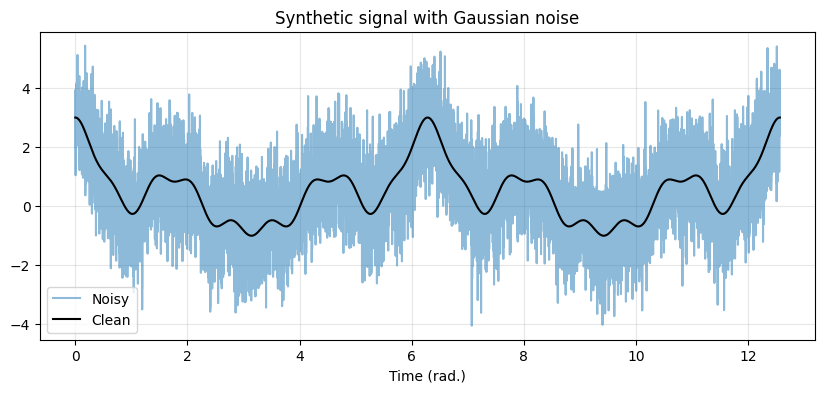

In [2]:
rng = np.random.default_rng(42)
N = 10001
time = np.linspace(0, 4 * np.pi, N)
clean = sum(np.cos(i * time) ** i for i in range(1, 4))
noisy = clean + rng.normal(size=N)

plt.plot(time, noisy, alpha=0.5, label="Noisy")
plt.plot(time, clean, "k", label="Clean")
plt.xlabel("Time (rad.)"); plt.legend(); plt.title("Synthetic signal with Gaussian noise")
plt.show()

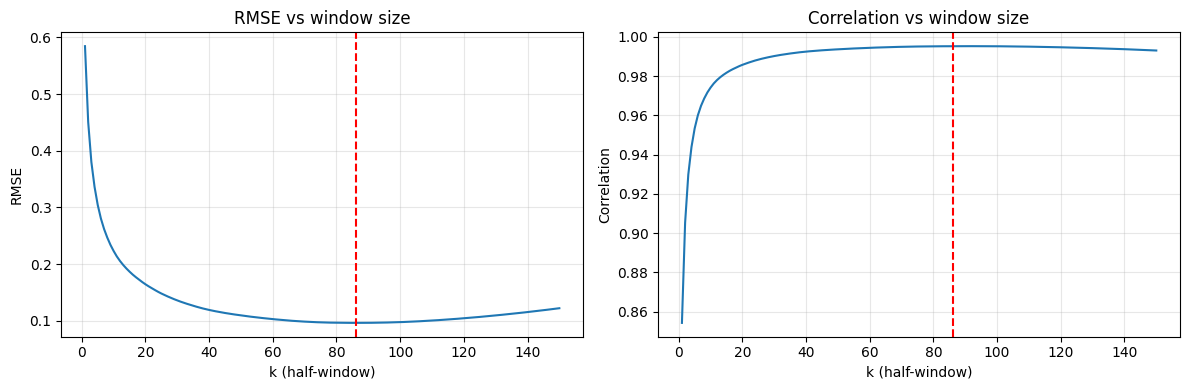

Noisy RMSE:        1.006
Best k:            86  ->  RMSE 0.096
SNR improvement:   20.4 dB


In [3]:
ks = np.arange(1, 151)
rmses = [rmse(clean, mean_filter(noisy, k)) for k in ks]
corrs = [correlation(clean, mean_filter(noisy, k)) for k in ks]
best_k = int(ks[np.argmin(rmses)])
best = mean_filter(noisy, best_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, rmses); ax[0].axvline(best_k, color="r", ls="--")
ax[0].set(title="RMSE vs window size", xlabel="k (half-window)", ylabel="RMSE")
ax[1].plot(ks, corrs); ax[1].axvline(best_k, color="r", ls="--")
ax[1].set(title="Correlation vs window size", xlabel="k (half-window)", ylabel="Correlation")
plt.tight_layout(); plt.show()

print(f"Noisy RMSE:        {rmse(clean, noisy):.3f}")
print(f"Best k:            {best_k}  ->  RMSE {rmse(clean, best):.3f}")
print(f"SNR improvement:   {snr_improvement_db(clean, noisy, best):.1f} dB")

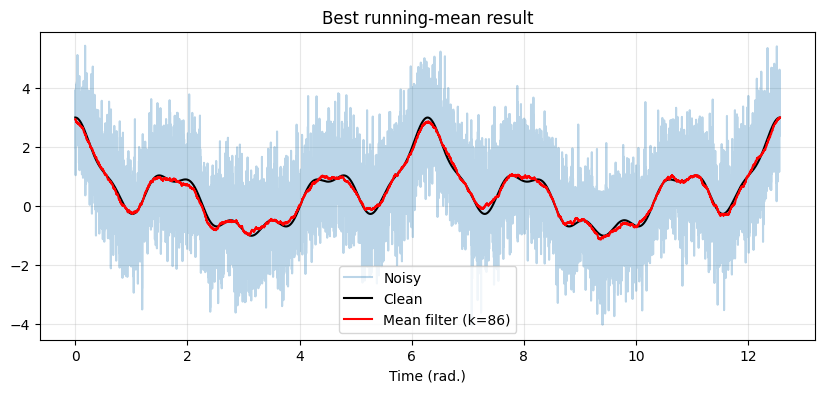

In [4]:
plt.plot(time, noisy, alpha=0.3, label="Noisy")
plt.plot(time, clean, "k", label="Clean")
plt.plot(time, best, "r", label=f"Mean filter (k={best_k})")
plt.xlabel("Time (rad.)"); plt.legend(); plt.title("Best running-mean result")
plt.show()

**Conclusion:** RMSE falls sharply as the window grows reaches a minimum around k = 86 then rises again because large windows flatten the signal's peaks.Too small window leaves noise in and too large a window distorts the signal.The correlation curve peaks at a slightly different k so the metric chosen decides the answer.

## 2. Spike noise: why the mean fails and the median works

The clean signal is a sawtooth-like curve. 10% of the points are replaced with large spikes (values 10 to 110).

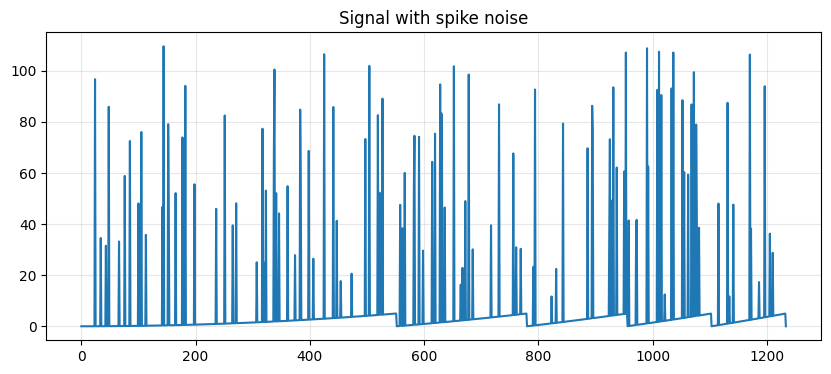

In [5]:
rng = np.random.default_rng(1)
pnts = 1234
clean2 = np.mod(np.linspace(0, 5, pnts) ** 2, 5)

spiky = clean2.copy()
spike_idx = rng.integers(0, pnts, int(0.1 * pnts))
spiky[spike_idx] = 10 + 100 * rng.random(len(spike_idx))

plt.plot(spiky); plt.title("Signal with spike noise"); plt.show()

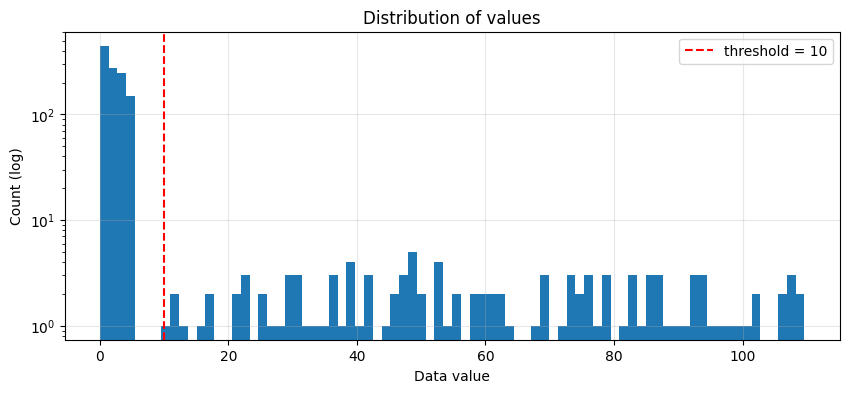

In [6]:
plt.hist(spiky, 80); plt.yscale("log")
plt.axvline(10, color="r", ls="--", label="threshold = 10")
plt.xlabel("Data value"); plt.ylabel("Count (log)"); plt.legend()
plt.title("Distribution of values"); plt.show()

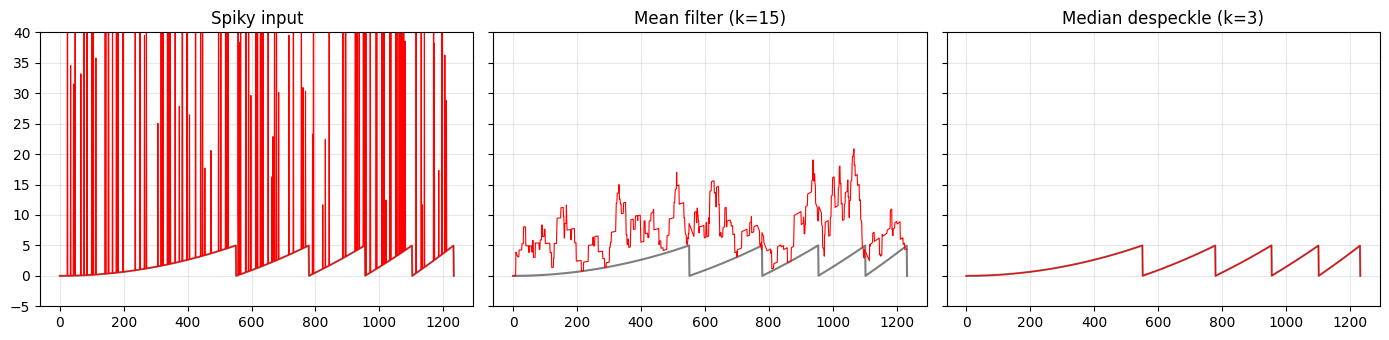

RMSE  spiky input:       19.845
RMSE  mean filter:       6.548
RMSE  median despeckle:  0.011


In [7]:
mean_out = mean_filter(spiky, 15)
despeckled = despeckle(spiky, threshold=10, k=3)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, y, title in zip(ax, (spiky, mean_out, despeckled),
                       ("Spiky input", "Mean filter (k=15)", "Median despeckle (k=3)")):
    a.plot(clean2, "k", alpha=0.5); a.plot(y, "r", lw=0.8); a.set_title(title)
ax[0].set_ylim(-5, 40)
plt.tight_layout(); plt.show()

print(f"RMSE  spiky input:       {rmse(clean2, spiky):.3f}")
print(f"RMSE  mean filter:       {rmse(clean2, mean_out):.3f}")
print(f"RMSE  median despeckle:  {rmse(clean2, despeckled):.3f}")

**conclusion:** The mean filter spreads each spike across its neighbours so the error drops (about 19.8 to 6.5 RMSE) but stays high. Replacing only the flagged points with the local median removes the spikes almost completely (RMSE about 0.01) and leaves every other sample untouched. For impulse noise an outlier-aware filter needs to be used not an average one.

## 3. Real data: EKG recording

RMSE  noisy:                123.75
RMSE  median (dropouts):    100.88
RMSE  median + mean:        40.53


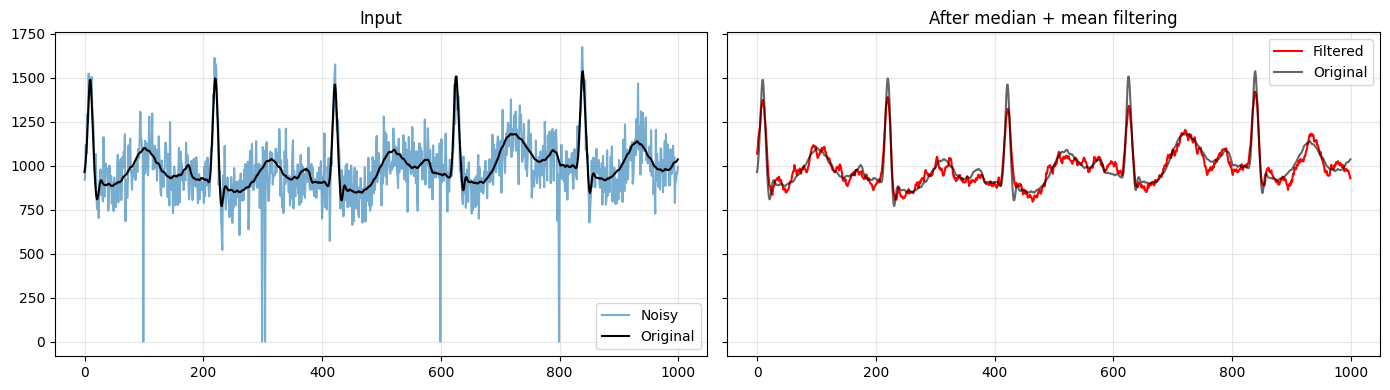

In [8]:
path = Path("data") / "EKG_signals.csv"

if not path.exists():
    print(f"{path} not found. Add the file and re-run this section.")
else:
    df = pd.read_csv(path, names=["noisy", "orig"])
    step1 = despeckle(df["noisy"].to_numpy(), threshold=300, k=7, above=False)  # fix dropouts
    step2 = mean_filter(step1, 5)                                              # smooth the rest
    clean3 = df["orig"].to_numpy()

    print(f"RMSE  noisy:                {rmse(clean3, df['noisy']):.2f}")
    print(f"RMSE  median (dropouts):    {rmse(clean3, step1):.2f}")
    print(f"RMSE  median + mean:        {rmse(clean3, step2):.2f}")

    fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    ax[0].plot(df["noisy"], alpha=0.6, label="Noisy"); ax[0].plot(clean3, "k", label="Original")
    ax[0].legend(); ax[0].set_title("Input")
    ax[1].plot(step2, "r", label="Filtered"); ax[1].plot(clean3, "k", alpha=0.6, label="Original")
    ax[1].legend(); ax[1].set_title("After median + mean filtering")
    plt.tight_layout(); plt.show()

**conclusion:** The recording has 5 dropout samples (values near 0).Replacing them with a local median lowers RMSE from 123.8 to 100.9 because a few huge errors dominate the score. The running mean (k = 5) then brings it to 40.5 about a 9.7 dB SNR improvement.The plot also shows the cost--> the sharp R-peaks come out lower than the original because averaging flattens narrow features.A window of k = 3 to 5 gives the lowest RMSE here and larger windows blur the peaks further.

## Summary

- The best filter depends on the noise type: **averaging** for Gaussian noise, **median-based replacement** for spikes.
- The window size is a trade-off between noise removal and signal distortion, and it should be chosen by measuring against a clean reference.
- Mean filtering a spiky signal gives a misleading improvement: the error drops, but the spikes are only smeared out.
- Limitations: all results use signals with a known clean version.